In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import xarray as xr
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_process import ArmaProcess
#from matplotlib.colors import TwoSlopeNorm

import cartopy
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths
import glob

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


#### Upload PI

In [2]:
## O2sat
constraint = iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2sat')

path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['_piControl_r1i1p1f1_gn_100101-110012_100yr_mean_regridded_360x385_intlevel.nc',
                   '_piControl_5021-5120_regridded_385x360_ann_mean_intlevel.nc',
                   '_piControl_r1i2p1f1_gn_195001-204912_regridded_100yr_mean_385x360_intlevel.nc',
                   '_piControl_6401_6500.codeO2sat_regridded_360x385_100yr_mean_intlevel.nc',
                   '_piControl_r1i1p1f2_gr1_225001-234912_100yr_mean_regridded_360x385_intlevel.nc',
                   '_f19_tn11_02.micom.hy.1600-1699_regridded_ann_mean_intlevel.nc',
                  '_piControl_r1i1p1f1_gr_200101-210012_regridded_100yr_mean_intlevel.nc']
PI_models_o2sat = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+'o2sat_Omon_'+models[i]+names_models_pi[i], constraint)
    PI_models_o2sat.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [3]:
## O2
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_pi_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_HadCM3_piControl_r1i1p1f1_5021-5120_regridded_385x360_ann_mean_intlevel.nc',
                   'o2_Oyr_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_3550-3849_fixed_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_KCM_piControl_r1i1p1f1_6401_6500_100yr_mean_intlevel.nc',
                   'o2_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_piControl_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_piControl_r1i1p1f1_gr_2001-2100_regridded_100yr_mean_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer13'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

PI_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversi

#### Upload LIG

In [4]:
### o2sat
constraint = iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2sat')

path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['_lig127k_r1i1p1f1_gn_100101-110012_100yr_mean_regridded_360x385_intlevel.nc',
                   '_lig127k_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                   '_lig127k_r1i1p1f1_gn_195001-204912_regridded_385x360_100yr_mean_intlevel.nc',
                   '_lig127k_4901_5000.codeO2sat_regridded_360x385_100yr_mean_intlevel.nc',
                   '_lig127k_r1i1p1f2_gr1_330001-339912_100yr_mean_regridded_360x385_intlevel.nc',
                    '_f19_tn11_01_127ka.micom.hy.1600-1699_regridded_ann_mean_intlevel.nc',
                   '_lig127k_r1i1p1f1_gr_210101-220012_regridded_100yr_mean_intlevel.nc']
LIG_models_o2sat = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+'o2sat_Omon_'+models[i]+names_models_lig[i], constraint)
    LIG_models_o2sat.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [5]:
## O2
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_lig_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_HadCM3_lig127k_r1i1p1f1_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                   'o2_Oyr_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_1850-1949_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_KCM_lig127k_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'o2_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_lig127k_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_lig127k_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2_raw'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer13'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

LIG_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

#### Upload masks

In [6]:
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'

masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
# Open
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [7]:
## Open masks
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'
masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
##
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

## O2sat and AOU

In [8]:
AOU_PI = [PI_models_o2sat[n].copy(data=PI_models_o2sat[n].data-PI_models_o2[n].data*(1 if n == 0 or n == 1 else 1e6 if n == 3 else 1e3)) 
    for n in range(np.size(PI_models_o2sat))]
AOU_LIG = [LIG_models_o2sat[n].copy(data=LIG_models_o2sat[n].data-LIG_models_o2[n].data*(1 if n == 0 or n == 1 else 1e6 if n == 3 else 1e3)) 
    for n in range(np.size(LIG_models_o2sat))]

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:1026: RuntimeWarning: overflow encountered in multiply
  result = self.f(da, db, *args, **kwargs)


### Differences

In [9]:
### O2sat diff
dif_o2sat = []

for i in range (np.size(PI_models_o2sat)):
    dif = LIG_models_o2sat[i].data-PI_models_o2sat[i].data
    dif_cube = PI_models_o2sat[i].copy(data = dif)
    dif_o2sat.append(dif_cube)

In [10]:
### AOU diff
dif_AOU = []

for i in range (np.size(AOU_PI)):
    dif = AOU_LIG[i].data-AOU_PI[i].data
    dif_cube = AOU_PI[i].copy(data = dif)
    dif_AOU.append(dif_cube)

In [11]:
### O2 diff
dif_o2 = []

for i in range (np.size(PI_models_o2)):
    dif = LIG_models_o2[i].data-PI_models_o2[i].data
    if i == 3:
        dif_cube = PI_models_o2[i].copy(data = dif*1e6)
    elif i == 2 or i == 4 or i == 5 or i == 6:
        dif_cube = PI_models_o2[i].copy(data = dif*1e3)
    else:
        dif_cube = PI_models_o2[i].copy(data = dif*1)
    dif_o2.append(dif_cube)

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:1026: RuntimeWarning: overflow encountered in multiply
  result = self.f(da, db, *args, **kwargs)


### Masking

In [12]:
def broadcast_masks_to_models(models, atlantic_mask, pacific_mask, indian_mask):
    "Input: lists iof iris cubes.Output: dictionary of broadcasted mask cubes by basin"
    broadcasted_masks = {"atlantic": [], "pacific": [], "indian": []}
    
    for model in models:
        shape = model.shape  # (depth, lat, lon) or similar
        
        # Broadcast each mask
        atl_broadcast = np.broadcast_to(atlantic_mask.data, shape)
        pac_broadcast = np.broadcast_to(pacific_mask.data, shape)
        ind_broadcast = np.broadcast_to(indian_mask.data, shape)
        
        # Replace NaNs with masked values
        atl_masked = np.ma.masked_invalid(atl_broadcast)
        pac_masked = np.ma.masked_invalid(pac_broadcast)
        ind_masked = np.ma.masked_invalid(ind_broadcast)
        
        # Create cubes with the same metadata as the model
        broadcasted_masks["atlantic"].append(model.copy(data=atl_masked))
        broadcasted_masks["pacific"].append(model.copy(data=pac_masked))
        broadcasted_masks["indian"].append(model.copy(data=ind_masked))
    
    return broadcasted_masks

In [13]:
PI_masks = broadcast_masks_to_models(AOU_PI, atlantic_mask, pacific_mask, indian_mask)
LIG_masks = broadcast_masks_to_models(AOU_LIG, atlantic_mask, pacific_mask, indian_mask)

PI_masks2 = broadcast_masks_to_models(PI_models_o2, atlantic_mask, pacific_mask, indian_mask)
LIG_masks2 = broadcast_masks_to_models(LIG_models_o2, atlantic_mask, pacific_mask, indian_mask)

### Setup the data

In [14]:
### PI data by basin
## O2sat
atlantic_masked_O2sat_PI = [m * mask for m, mask in zip(PI_models_o2sat, PI_masks["atlantic"])]
indian_masked_O2sat_PI = [m * mask for m, mask in zip(PI_models_o2sat, PI_masks["indian"])]
pacific_masked_O2sat_PI = [m * mask for m, mask in zip(PI_models_o2sat, PI_masks["pacific"])]
## AOU
atlantic_masked_AOU_PI = [m * mask for m, mask in zip(AOU_PI, PI_masks["atlantic"])]
indian_masked_AOU_PI = [m * mask for m, mask in zip(AOU_PI, PI_masks["indian"])]
pacific_masked_AOU_PI = [m * mask for m, mask in zip(AOU_PI, PI_masks["pacific"])]
## O2
atlantic_masked_O2_PI = [m * mask for m, mask in zip(PI_models_o2, PI_masks2["atlantic"])]
indian_masked_O2_PI = [m * mask for m, mask in zip(PI_models_o2, PI_masks2["indian"])]
pacific_masked_O2_PI = [m * mask for m, mask in zip(PI_models_o2, PI_masks2["pacific"])]

In [15]:
### LIG data by basin
## O2sat
atlantic_masked_O2sat_LIG = [m * mask for m, mask in zip(LIG_models_o2sat, LIG_masks["atlantic"])]
indian_masked_O2sat_LIG = [m * mask for m, mask in zip(LIG_models_o2sat, LIG_masks["indian"])]
pacific_masked_O2sat_LIG = [m * mask for m, mask in zip(LIG_models_o2sat, LIG_masks["pacific"])]
## AOU
atlantic_masked_AOU_LIG = [m * mask for m, mask in zip(AOU_LIG, LIG_masks["atlantic"])]
indian_masked_AOU_LIG = [m * mask for m, mask in zip(AOU_LIG, LIG_masks["indian"])]
pacific_masked_AOU_LIG = [m * mask for m, mask in zip(AOU_LIG, LIG_masks["pacific"])]
## O2
atlantic_masked_O2_LIG = [m * mask for m, mask in zip(LIG_models_o2, LIG_masks2["atlantic"])]
indian_masked_O2_LIG = [m * mask for m, mask in zip(LIG_models_o2, LIG_masks2["indian"])]
pacific_masked_O2_LIG = [m * mask for m, mask in zip(LIG_models_o2, LIG_masks2["pacific"])]

In [16]:
#### PI zonal means
## O2sat
atl_an_zmean_O2sat_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_O2sat_PI]
ind_an_zmean_O2sat_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_O2sat_PI]
pac_an_zmean_O2sat_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_O2sat_PI]
## AOU
atl_an_zmean_aou_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_AOU_PI]
ind_an_zmean_aou_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_AOU_PI]
pac_an_zmean_aou_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_AOU_PI]
## O2
atl_an_zmean_O2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_O2_PI]
ind_an_zmean_O2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_O2_PI]
pac_an_zmean_O2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_O2_PI]

#### LIG zonal means
## O2sat
atl_an_zmean_O2sat_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_O2sat_LIG]
ind_an_zmean_O2sat_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_O2sat_LIG]
pac_an_zmean_O2sat_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_O2sat_LIG]
## AOU
atl_an_zmean_aou_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_AOU_LIG]
ind_an_zmean_aou_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_AOU_LIG]
pac_an_zmean_aou_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_AOU_LIG]
## O2
atl_an_zmean_O2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_O2_LIG]
ind_an_zmean_O2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_O2_LIG]
pac_an_zmean_O2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_O2_LIG]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


In [17]:
### O2sat differences
dif_o2sat_atl = []
dif_o2sat_pac = []
dif_o2sat_ind = []

for i in range (np.size(atl_an_zmean_O2sat_PI)):
    dif_atl = atl_an_zmean_O2sat_LIG[i].data-atl_an_zmean_O2sat_PI[i].data
    dif_pac = pac_an_zmean_O2sat_LIG[i].data-pac_an_zmean_O2sat_PI[i].data
    dif_ind = ind_an_zmean_O2sat_LIG[i].data-ind_an_zmean_O2sat_PI[i].data

    dif_atl_cube = atl_an_zmean_O2sat_PI[i].copy(data = dif_atl)
    dif_pac_cube = pac_an_zmean_O2sat_PI[i].copy(data = dif_pac)
    dif_ind_cube = ind_an_zmean_O2sat_PI[i].copy(data = dif_ind)
    
    dif_o2sat_atl.append(dif_atl_cube)
    dif_o2sat_pac.append(dif_pac_cube)
    dif_o2sat_ind.append(dif_ind_cube)

In [18]:
### AOU Differences
dif_aou_atl = []
dif_aou_pac = []
dif_aou_ind = []

for i in range (np.size(ind_an_zmean_aou_PI)):
    dif_atl = atl_an_zmean_aou_LIG[i].data-atl_an_zmean_aou_PI[i].data
    dif_pac = pac_an_zmean_aou_LIG[i].data-pac_an_zmean_aou_PI[i].data
    dif_ind = ind_an_zmean_aou_LIG[i].data-ind_an_zmean_aou_PI[i].data

    dif_atl_cube = atl_an_zmean_aou_PI[i].copy(data = dif_atl)
    dif_pac_cube = pac_an_zmean_aou_PI[i].copy(data = dif_pac)
    dif_ind_cube = ind_an_zmean_aou_PI[i].copy(data = dif_ind)
    
    dif_aou_atl.append(dif_atl_cube)
    dif_aou_pac.append(dif_pac_cube)
    dif_aou_ind.append(dif_ind_cube)

In [19]:
### O2 differences
dif_o2_atl = []
dif_o2_pac = []
dif_o2_ind = []

for i in range (np.size(atl_an_zmean_O2sat_PI)):
    
    dif_atl = atl_an_zmean_O2_LIG[i].data-atl_an_zmean_O2_PI[i].data
    dif_pac = pac_an_zmean_O2_LIG[i].data-pac_an_zmean_O2_PI[i].data
    dif_ind = ind_an_zmean_O2_LIG[i].data-ind_an_zmean_O2_PI[i].data

    dif_atl_cube = atl_an_zmean_O2_PI[i].copy(data = dif_atl)
    dif_pac_cube = pac_an_zmean_O2_PI[i].copy(data = dif_pac)
    dif_ind_cube = ind_an_zmean_O2_PI[i].copy(data = dif_ind)
    
    if i == 3:
        dif_atl_cube_corr = dif_atl_cube*1e6
        dif_pac_cube_corr = dif_pac_cube*1e6
        dif_ind_cube_corr = dif_ind_cube*1e6
    elif i == 2 or i == 4 or i == 5 or i == 6:
        dif_atl_cube_corr = dif_atl_cube*1e3
        dif_pac_cube_corr = dif_pac_cube*1e3
        dif_ind_cube_corr = dif_ind_cube*1e3
    else:
        dif_atl_cube_corr = dif_atl_cube*1
        dif_pac_cube_corr = dif_pac_cube*1
        dif_ind_cube_corr = dif_ind_cube*1
        
    dif_o2_atl.append(dif_atl_cube_corr)
    dif_o2_pac.append(dif_pac_cube_corr)
    dif_o2_ind.append(dif_ind_cube_corr)

In [20]:
### O2 MMM differences
# Calculate multi-model means with converted data
MMM_diff_o2_atl = sum([dif_o2_atl[i].data for i in range(np.size(dif_o2_atl))])/7
MMM_diff_o2_pac = sum([dif_o2_pac[i].data for i in range(np.size(dif_o2_pac))])/7
MMM_diff_o2_ind = sum([dif_o2_ind[i].data for i in range(np.size(dif_o2_ind))])/7

# Convert arrays to iris cubes
MMM_diff_o2_atl_cube = dif_o2_atl[0].copy(data = MMM_diff_o2_atl)
MMM_diff_o2_pac_cube = dif_o2_pac[0].copy(data = MMM_diff_o2_pac)
MMM_diff_o2_ind_cube = dif_o2_ind[0].copy(data = MMM_diff_o2_ind)

### Contribution

In [21]:
def calculate_o2_contributions(dif_o2sat_atl, dif_aou_atl, dif_o2_atl, threshold=1e-10):
    """
    Calculate percentage contributions of O2sat and AOU to total O2 changes.
    ΔO2 = ΔO2sat - ΔAOU
    % O2sat contribution = (ΔO2sat / ΔO2) * 100
    % AOU contribution   = (-ΔAOU  / ΔO2) * 100
    """
    pct_o2sat_list = []
    pct_aou_list   = []

    for i, (cube_o2sat, cube_aou, cube_o2) in enumerate(
            zip(dif_o2sat_atl, dif_aou_atl, dif_o2_atl)):

        # Extract data
        o2sat_data = cube_o2sat.data.copy().astype(float)
        aou_data   = cube_aou.data.copy().astype(float)
        o2_data    = cube_o2.data.copy().astype(float)

        # threshold for delta O2
        existing_mask = np.zeros(o2_data.shape, dtype=bool)
        if np.ma.is_masked(o2_data):
            existing_mask = np.ma.getmaskarray(o2_data)

        near_zero_mask = np.abs(o2_data) < threshold
        full_mask      = existing_mask | near_zero_mask

        # Division
        o2_masked    = np.ma.array(o2_data,    mask=full_mask)
        o2sat_masked = np.ma.array(o2sat_data, mask=full_mask)
        aou_masked   = np.ma.array(aou_data,   mask=full_mask)

        # contribution: ΔO2sat / ΔO2 * 100
        pct_o2sat = (o2sat_masked / o2_masked) * 100.0

        # contribution: -ΔAOU / ΔO2 * 100
        pct_aou   = (-aou_masked  / o2_masked) * 100.0

        # Iris cubes
        pct_o2sat_cube = cube_o2.copy(data=pct_o2sat)
        pct_aou_cube   = cube_o2.copy(data=pct_aou)

        pct_o2sat_cube.rename('percentage_contribution_o2sat')
        pct_aou_cube.rename('percentage_contribution_aou')

        pct_o2sat_cube.units = '%'
        pct_aou_cube.units   = '%'

        pct_o2sat_list.append(pct_o2sat_cube)
        pct_aou_list.append(pct_aou_cube)

    return pct_o2sat_list, pct_aou_list

In [22]:
pct_o2sat_pac, pct_aou_pac = calculate_o2_contributions(dif_o2sat_pac, dif_aou_pac, dif_o2_pac,threshold=1e-3 )
pct_o2sat_atl, pct_aou_atl = calculate_o2_contributions(dif_o2sat_atl, dif_aou_atl, dif_o2_atl,threshold=1e-3 )
pct_o2sat_ind, pct_aou_ind = calculate_o2_contributions(dif_o2sat_ind, dif_aou_ind, dif_o2_ind,threshold=1e-3 )
pct_o2sat_3d, pct_aou_3d = calculate_o2_contributions(dif_o2sat, dif_AOU, dif_o2,threshold=1e-3 )

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/ipykernel/__main__.py:24: RuntimeWarning: invalid value encountered in less


### Plot

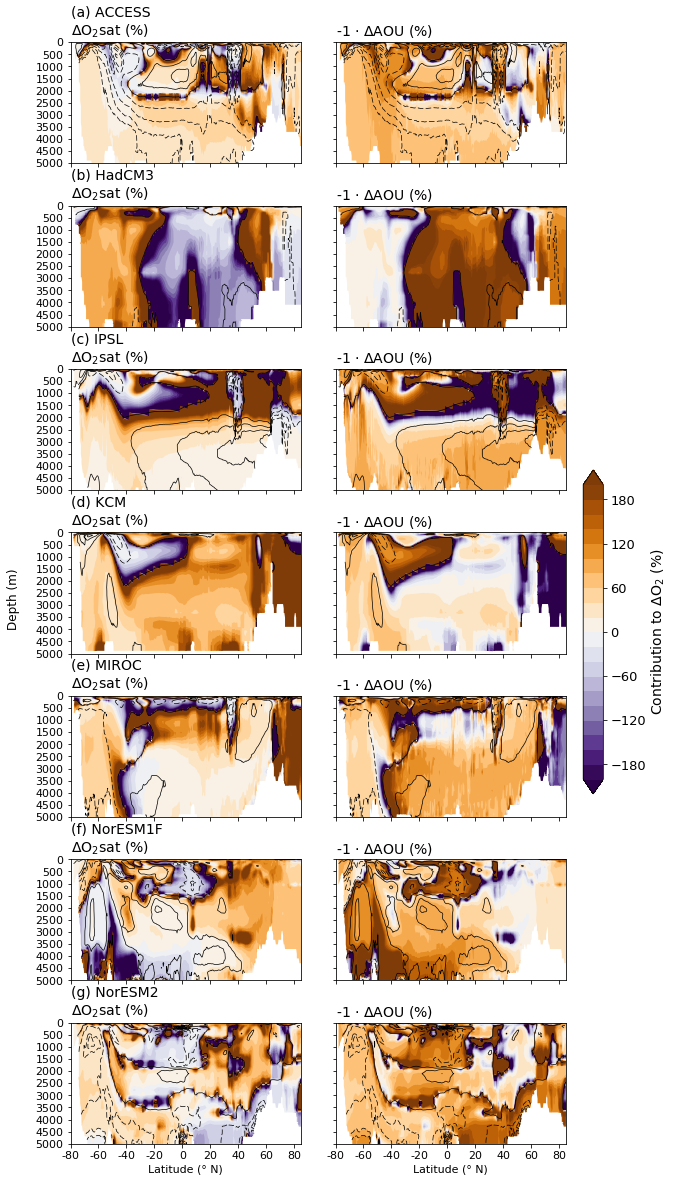

In [23]:
#### Plot contributions Atlantic
axes_o2sat = []
axes_aou   = []

fig, axes = plt.subplots(7, 2, figsize=(8, 18))

axes_o2sat = axes[:, 0]  
axes_aou   = axes[:, 1] 

titles = ['(a) ACCESS', '(b) HadCM3', '(c) IPSL', '(d) KCM','(e) MIROC',  '(f) NorESM1F', '(g) NorESM2']
depth  = ['depth', 'depth_1', 'Vertical T levels', 'plev','ocean sigma over z coordinate', 'depth', 'depth']
last_im = None

for n, (ax_sat, ax_aou_ax, t) in enumerate(zip(axes_o2sat, axes_aou, titles)):

    for ax, simulations, label in [
            (ax_sat,    pct_o2sat_atl, r'$\Delta$O$_2$sat (%)'),
            (ax_aou_ax, pct_aou_atl,   r'-1 · $\Delta$AOU (%)'),]:

        ax.set_yticks(np.arange(0, 5000+500, 500))
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=11)
        ax.tick_params(axis='y', labelsize=11)
        ax.set_ylim(0, 5000)
        ax.set_xlim(-80, 85)
        levels = np.arange(-200, 200+20, 20)
        levels_diff = np.arange(-40, 40+10, 10)
        
        if ax is ax_sat:
            ax.set_title('{}\n{}'.format(t, label), fontsize=14, loc='left')
        else:
            ax.set_title(label, fontsize=14, loc='left')

        last_im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], levels=levels, cmap='PuOr_r', axes=ax, extend='both')
        cs = iplt.contour(dif_o2_atl[n], coords=['latitude', depth[n]], levels=levels_diff, axes=ax, colors='k', linewidths=0.7)
        
        if n in [1, 2, 3, 4]:
            ax.invert_yaxis()

        # Remove y-axis labels on AOU
        if ax is ax_aou_ax:
            ax.set_yticklabels([])
        # x labels bottom row only
        if n == len(titles) - 1:                      
            ax.set_xlabel('Latitude (° N)', fontsize=11)
        else:
            ax.tick_params(axis='x', labelbottom=False)   

# Colourbar
cbar_ax = fig.add_axes([0.95, 0.35, 0.035, 0.25]) # [left, bottom, width, height]
cbar = fig.colorbar(last_im, cax=cbar_ax)
cbar.ax.set_ylabel(r'Contribution to $\Delta$O$_2$ (%)', size=14)
cbar.ax.tick_params(labelsize=13)

plt.subplots_adjust(left=0.06, bottom=0.08, right=0.92, top=0.93, wspace=0.15, hspace=0.35)
fig.text(-0.05, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=12)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/aou_o2sat_contributions_zonal_mean_atlantic_v2.png',bbox_inches='tight', dpi=300, format='png')
plt.show()

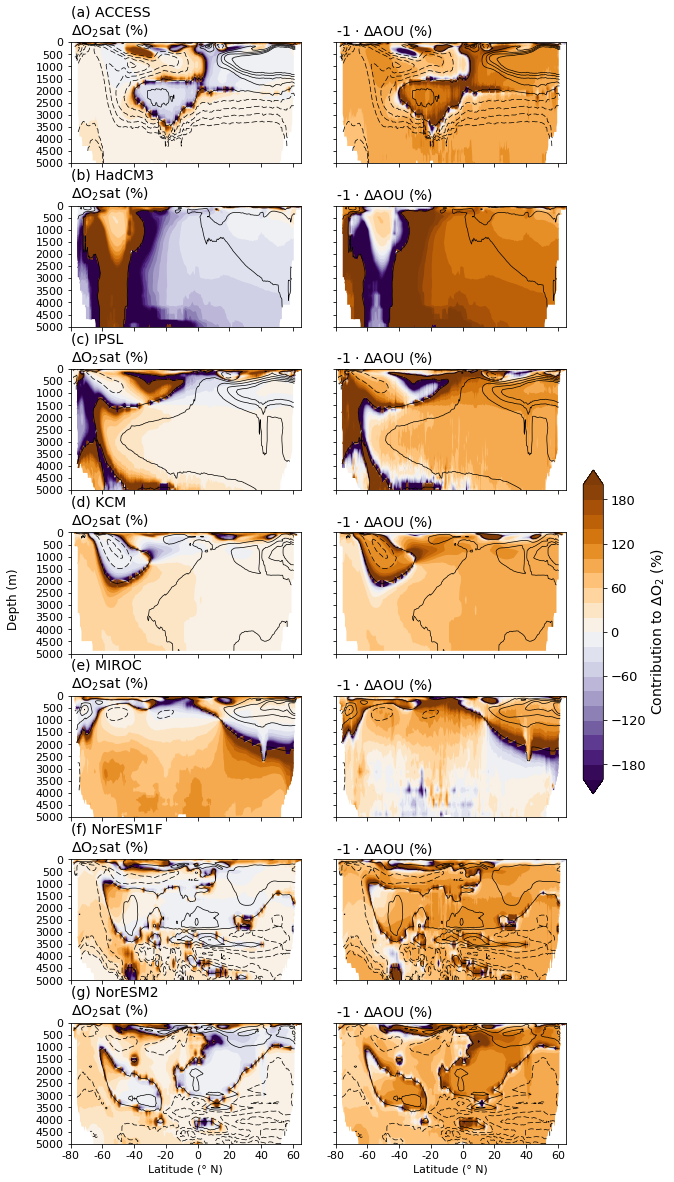

In [24]:
#### Plot contributions Pacific
axes_o2sat = []
axes_aou   = []

fig, axes = plt.subplots(7, 2, figsize=(8, 18))

axes_o2sat = axes[:, 0]
axes_aou   = axes[:, 1]

titles = ['(a) ACCESS', '(b) HadCM3', '(c) IPSL', '(d) KCM','(e) MIROC',  '(f) NorESM1F', '(g) NorESM2']
depth  = ['depth', 'depth_1', 'Vertical T levels', 'plev','ocean sigma over z coordinate', 'depth', 'depth']

levels = np.arange(-200, 200+20, 20)
last_im = None

for n, (ax_sat, ax_aou_ax, t) in enumerate(zip(axes_o2sat, axes_aou, titles)):

    for ax, simulations, label in [
            (ax_sat,    pct_o2sat_pac, r'$\Delta$O$_2$sat (%)'),
            (ax_aou_ax, pct_aou_pac,   r'-1 · $\Delta$AOU (%)')]:

        ax.set_yticks(np.arange(0, 5000+500, 500))
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=11)
        ax.tick_params(axis='y', labelsize=11)
        ax.set_ylim(0, 5000)
        ax.set_xlim(-80, 65)
        levels = np.arange(-200, 200+20, 20)
        levels_diff = np.arange(-40, 40+10, 10)

        if ax is ax_sat:
            ax.set_title('{}\n{}'.format(t, label), fontsize=14, loc='left')
        else:
            ax.set_title(label, fontsize=14, loc='left')

        last_im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], levels=levels, cmap='PuOr_r', axes=ax, extend='both')
        cs = iplt.contour(dif_o2_pac[n], coords=['latitude', depth[n]], levels=levels_diff, axes=ax, colors='k', linewidths=0.7)

        if n in [1, 2, 3, 4]:
            ax.invert_yaxis()

        # Remove y-axis labels on AOU
        if ax is ax_aou_ax:
            ax.set_yticklabels([])
        # x labels on the bottom row only
        if n == len(titles) - 1:                  
            ax.set_xlabel('Latitude (° N)', fontsize=11)
        else:
            ax.tick_params(axis='x', labelbottom=False)

# Colourbar
cbar_ax = fig.add_axes([0.95, 0.35, 0.035, 0.25]) # [left, bottom, width, height]
cbar = fig.colorbar(last_im, cax=cbar_ax)
cbar.ax.set_ylabel(r'Contribution to $\Delta$O$_2$ (%)', size=14)
cbar.ax.tick_params(labelsize=13)

plt.subplots_adjust(left=0.06, bottom=0.08, right=0.92, top=0.93, wspace=0.15, hspace=0.35)
fig.text(-0.05, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=12)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/aou_o2sat_contributions_zonal_mean_Pacific.png',bbox_inches='tight', dpi=300, format='png')
plt.show()

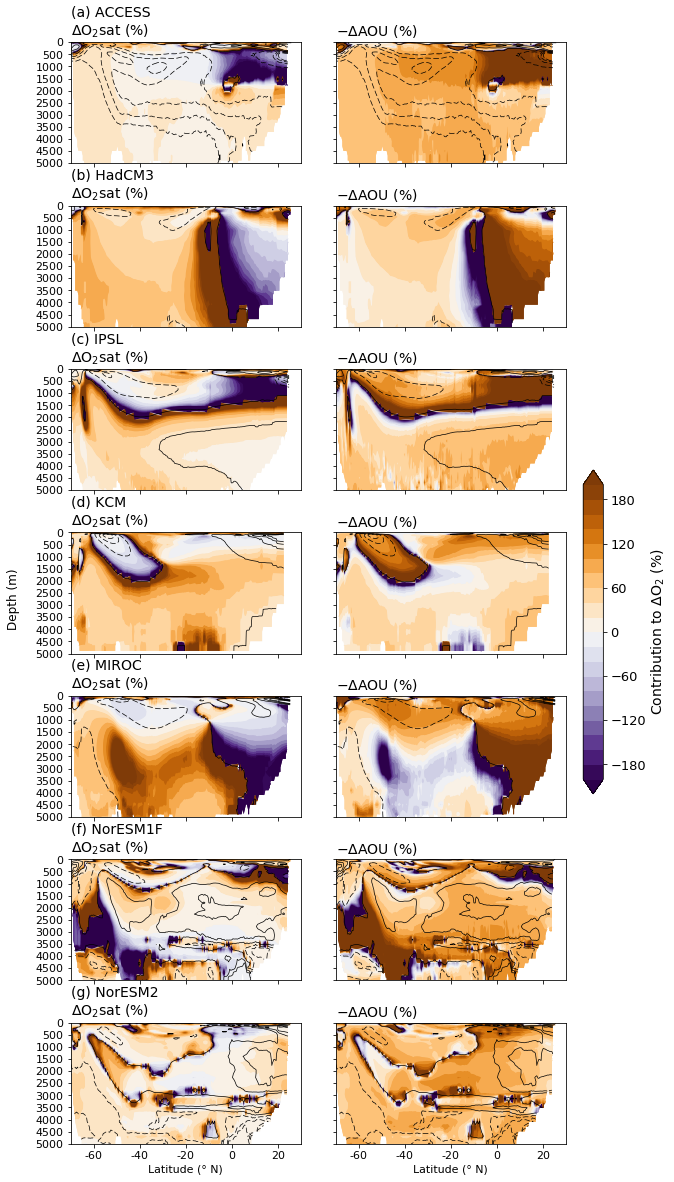

In [25]:
#### Plot contributions Indian
axes_o2sat = []
axes_aou   = []

fig, axes = plt.subplots(7, 2, figsize=(8, 18))

axes_o2sat = axes[:, 0]  
axes_aou   = axes[:, 1]  

titles = ['(a) ACCESS', '(b) HadCM3', '(c) IPSL', '(d) KCM','(e) MIROC',  '(f) NorESM1F', '(g) NorESM2']
depth  = ['depth', 'depth_1', 'Vertical T levels', 'plev','ocean sigma over z coordinate', 'depth', 'depth']

levels = np.arange(-200, 200+20, 20)
last_im = None

for n, (ax_sat, ax_aou_ax, t) in enumerate(zip(axes_o2sat, axes_aou, titles)):

    for ax, simulations, label in [
            (ax_sat,    pct_o2sat_ind, r'$\Delta$O$_2$sat (%)'),
            (ax_aou_ax, pct_aou_ind,   r'$-\Delta$AOU (%)')]:

        ax.set_yticks(np.arange(0, 5000+500, 500))
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=11)
        ax.tick_params(axis='y', labelsize=11)
        ax.set_ylim(0, 5000)
        ax.set_xlim(-70, 30)
        last_im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], levels=levels, cmap='PuOr_r', axes=ax, extend='both')

        if ax is ax_sat:
            ax.set_title('{}\n{}'.format(t, label), fontsize=14, loc='left')
        else:
            ax.set_title(label, fontsize=14, loc='left')
            
        levels_diff = np.arange(-40, 40+10, 10)
        last_im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], levels=levels, cmap='PuOr_r', axes=ax, extend='both')
        cs = iplt.contour(dif_o2_ind[n], coords=['latitude', depth[n]], levels=levels_diff, axes=ax, colors='k', linewidths=0.7)

        if n in [1, 2, 3, 4]:
            ax.invert_yaxis()

        # Remove y-axis on AOU
        if ax is ax_aou_ax:
            ax.set_yticklabels([])
        # x labels on the bottom row
        if n == len(titles) - 1:                      
            ax.set_xlabel('Latitude (° N)', fontsize=11)
        else:
            ax.tick_params(axis='x', labelbottom=False)   

# Colourbar
cbar_ax = fig.add_axes([0.95, 0.35, 0.035, 0.25]) # [left, bottom, width, height]
cbar = fig.colorbar(last_im, cax=cbar_ax)
cbar.ax.set_ylabel(r'Contribution to $\Delta$O$_2$ (%)', size=14)
cbar.ax.tick_params(labelsize=13)

plt.subplots_adjust(left=0.06, bottom=0.08, right=0.92, top=0.93, wspace=0.15, hspace=0.35)
fig.text(-0.05, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=12)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/aou_o2sat_contributions_zonal_mean_Indian.png',bbox_inches='tight', dpi=300, format='png')
plt.show()